In [ ]:
import os

os.environ.setdefault("PYRITE_MC_BACKEND", "cpu")
import marimo as mo
import matplotlib.pyplot as plt
import numpy as np

from pyrite.quantum import gaussian, hermite_gauss, laguerre_gauss, mixture, superpose

# Constructing transverse quantum states

[![Open in Molab](https://marimo.io/molab-shield.svg)](https://molab.marimo.io/github/Quantum-Light-Matter-Cooperative-QLMC/pyrite/blob/main/docs/notebooks/12-transverse-quantum-states.py)

Compare Gaussian, Hermite–Gaussian and Laguerre–Gaussian states,
then distinguish coherent interference from an incoherent mixture.
Coordinates and the **1.5 Å** waist are transverse to the beam.

In [ ]:
coordinates_ang = np.linspace(-5.0, 5.0, 101)
ground = gaussian(waist_ang=1.5, dimension=2)
hermite = hermite_gauss(1, 0, waist_ang=1.5)
positive = laguerre_gauss(ell=1, waist_ang=1.5)
negative = laguerre_gauss(ell=-1, waist_ang=1.5)

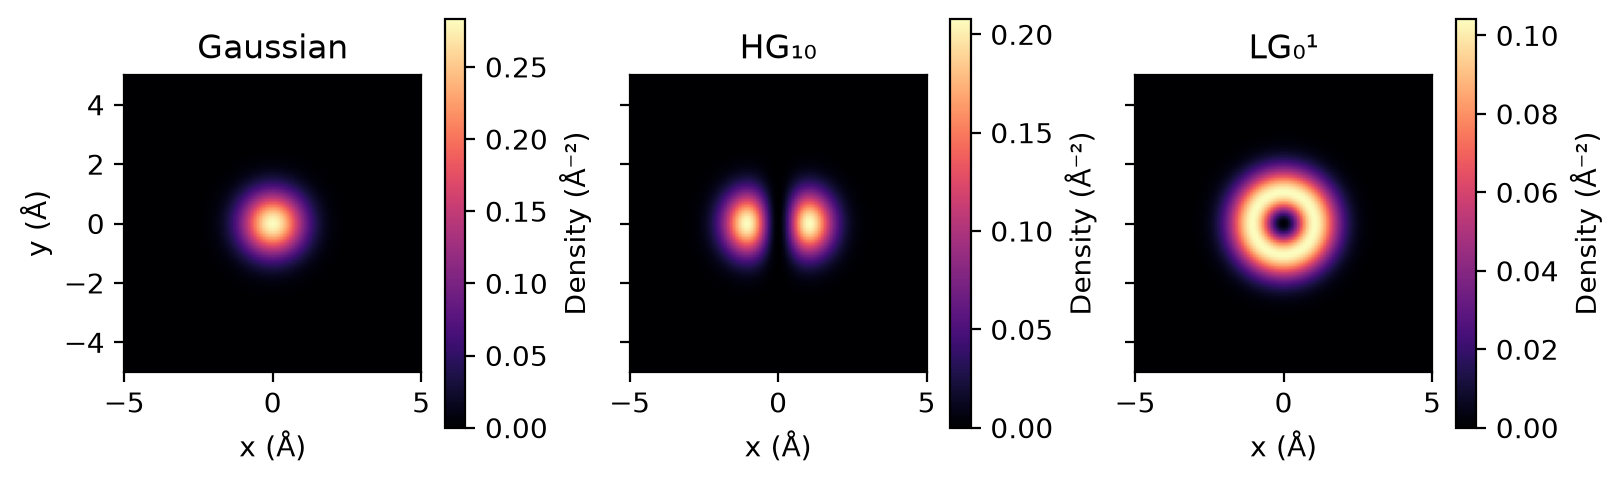

In [ ]:
fig_modes, _axes = plt.subplots(1, 3, figsize=(8, 3), layout="constrained", sharey=True)
for _ax, _state, _label in zip(
    _axes, (ground, hermite, positive), ("Gaussian", "HG₁₀", "LG₀¹"), strict=True
):
    _density = np.abs(_state.wavefunction(coordinates_ang, coordinates_ang)) ** 2
    _image = _ax.imshow(_density.T, origin="lower", extent=(-5, 5, -5, 5), cmap="magma", vmin=0)
    _ax.set(xlabel="x (Å)", title=_label)
    fig_modes.colorbar(_image, ax=_ax, shrink=0.7, label="Density (Å⁻²)")
_axes[0].set_ylabel("y (Å)")
fig_modes  # noqa: B018 - displayed by marimo

In [ ]:
coherent = superpose([(1.0, positive), (1.0j, negative)])
incoherent = mixture([(1.0, positive), (1.0, negative)])

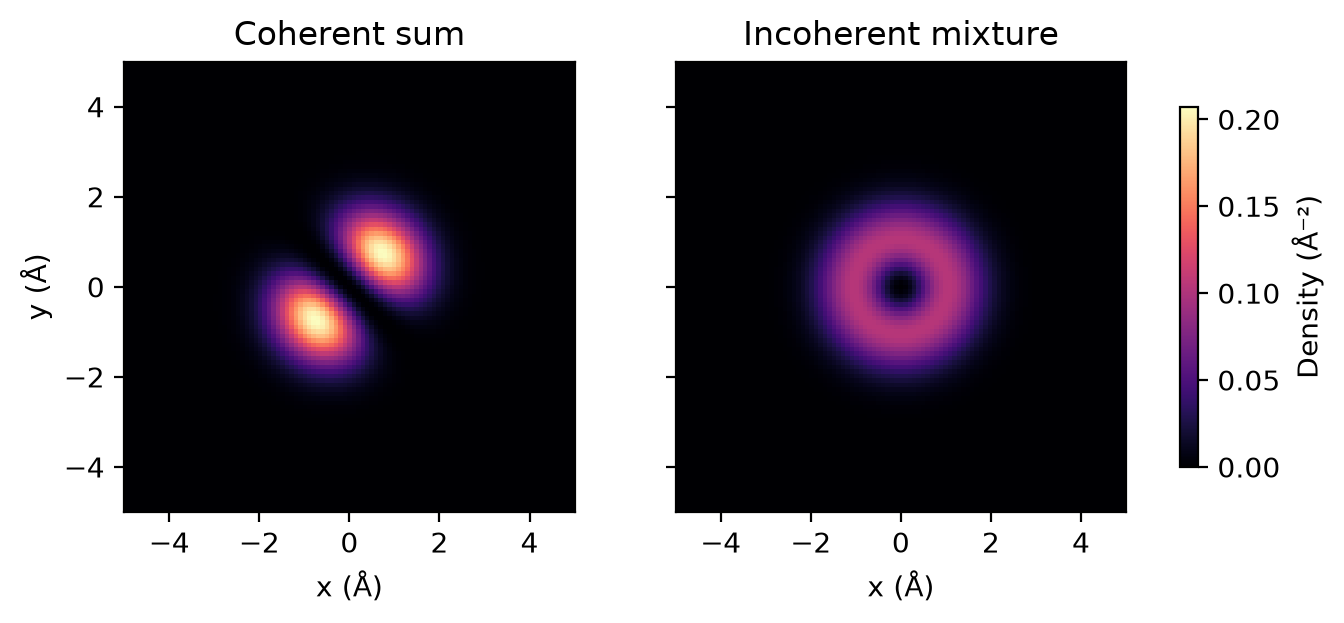

In [ ]:
coherent_density = np.abs(coherent.wavefunction(coordinates_ang, coordinates_ang)) ** 2
mixed_density = sum(
    _weight * np.abs(_state.wavefunction(coordinates_ang, coordinates_ang)) ** 2
    for _weight, _state in incoherent.components
)
fig_coherence, _axes = plt.subplots(1, 2, figsize=(7, 3), layout="constrained", sharey=True)
for _ax, _density, _label in zip(
    _axes,
    (coherent_density, mixed_density),
    ("Coherent sum", "Incoherent mixture"),
    strict=True,
):
    _image = _ax.imshow(
        _density.T,
        origin="lower",
        extent=(-5, 5, -5, 5),
        cmap="magma",
        vmin=0,
        vmax=float(coherent_density.max()),
    )
    _ax.set(xlabel="x (Å)", title=_label)
_axes[0].set_ylabel("y (Å)")
fig_coherence.colorbar(_image, ax=_axes, shrink=0.8, label="Density (Å⁻²)")
fig_coherence  # noqa: B018 - displayed by marimo

Coherent sums add amplitudes, including their relative phase; mixtures
add weighted densities and have no single wavefunction phase.
Each distribution integrates to one over the transverse plane.

Try changing the coherent relative phase from `1j` to `1.0`, or changing
the mixture weights. These are standalone states; their construction
does not imply admission to experimental channeling transport.

## Continue learning

Next: [Planar channeling and radiation](13-planar-channeling-radiation.ipynb).
The [quantum API](../../reference/python-api/quantum.md) separates runtime states
from portable specifications and experimental solvers.
See [quantum source contracts](../../reference/quantum-api.md) for dimensions,
normalization and production admission, and the
[quantum ensemble evidence](../../validation/channeling/cr-quantum-ensemble-metrics.md)
for mixture and overlap checks.

{download}`Download canonical Marimo notebook <../12-transverse-quantum-states.py>`